# Where do payments concentrate in synthetic Medicare claims?

This case study turns [CMS DE-SynPUF Sample 1](https://www.cms.gov/data-research/statistics-trends-and-reports/medicare-claims-synthetic-public-use-files/cms-2008-2010-data-entrepreneurs-synthetic-public-use-file-de-synpuf/de10-sample-1) into a payer-style analysis of inpatient and outpatient claim payments. The question is which member cohorts account for the most payments in this synthetic sample and how inpatient use differs across those cohorts.

## Data files & how to run

Place the following CSV files in `data/raw/`:

- `DE1_0_2008_Beneficiary_Summary_File_Sample_1.csv`
- `DE1_0_2008_to_2010_Inpatient_Claims_Sample_1.csv`
- `DE1_0_2008_to_2010_Outpatient_Claims_Sample_1.csv`

Run all cells in order (Cell → Run All). Dependencies: pandas, numpy, matplotlib.

## Load data

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# DE-SynPUF date fields (CLM_FROM_DT, CLM_ADMSN_DT, BENE_BIRTH_DT) are YYYYMMDD integers.
# Parsing without format= causes pandas to misinterpret them (e.g. as Unix -> 1970).
def parse_yyyymmdd(series):
    """Convert DE-SynPUF YYYYMMDD values to datetime. Required for correct time-series and charts."""
    s = series.astype(str).str.strip().str.replace(r'\.0$', '', regex=True)
    return pd.to_datetime(s, format="%Y%m%d", errors="coerce")

root = Path.cwd()
if not (root / "data" / "raw").is_dir():
    root = root.parent
DATA_DIR = root / "data" / "raw"


df_beneficiary = pd.read_csv(
    DATA_DIR / "DE1_0_2008_Beneficiary_Summary_File_Sample_1.csv"
)

df_inpatient = pd.read_csv(
    DATA_DIR / "DE1_0_2008_to_2010_Inpatient_Claims_Sample_1.csv"
)

df_outpatient = pd.read_csv(
    DATA_DIR / "DE1_0_2008_to_2010_Outpatient_Claims_Sample_1.csv", low_memory=False
)

print("Shapes:")
print("Beneficiary:", df_beneficiary.shape)
print("Inpatient:", df_inpatient.shape)
print("Outpatient:", df_outpatient.shape)

Shapes:
Beneficiary: (116352, 32)
Inpatient: (66773, 81)
Outpatient: (790790, 76)


## Data dictionary

Document key columns and meanings for beneficiary, inpatient, and outpatient datasets (e.g., IDs, dates, payment/cost fields, diagnosis codes).

In [2]:
# Use short names for clarity in this section
bene_df = df_beneficiary
inpatient_df = df_inpatient
outpatient_df = df_outpatient

# --- Print column names for each table ---
print("Beneficiary columns:", list(bene_df.columns))
print("\nInpatient columns:", list(inpatient_df.columns))
print("\nOutpatient columns:", list(outpatient_df.columns))

# --- Detect member ID column (must exist in all 3 tables) ---
MEMBER_ID_CANDIDATES = ["DESYNPUF_ID", "BENE_ID", "bene_id", "member_id"]
all_dfs = [bene_df, inpatient_df, outpatient_df]
member_id_col = None
for cand in MEMBER_ID_CANDIDATES:
    if all(cand in df.columns for df in all_dfs):
        member_id_col = cand
        break
if member_id_col is None:
    raise ValueError("No common member ID column found among DESYNPUF_ID, BENE_ID, bene_id, member_id")
print(f"\nMember ID column (in all 3 tables): {member_id_col}")

# --- Detect claim date column for claims tables (prefer from/start date) ---
DATE_CANDIDATES = ["CLM_FROM_DT", "CLM_ADMSN_DT", "CLM_THRU_DT"]  # from/start first, then fallback

def _first_found(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

inpatient_date_col = _first_found(inpatient_df, DATE_CANDIDATES)
outpatient_date_col = _first_found(outpatient_df, DATE_CANDIDATES)
print(f"Inpatient claim date column: {inpatient_date_col}")
print(f"Outpatient claim date column: {outpatient_date_col}")

# --- Detect cost column for claims tables ---
COST_CANDIDATES = ["CLM_PMT_AMT", "CLM_TOT_CHRG_AMT", "NCH_CLM_PMT_AMT"]
inpatient_cost_col = _first_found(inpatient_df, COST_CANDIDATES)
outpatient_cost_col = _first_found(outpatient_df, COST_CANDIDATES)
print(f"Inpatient cost column: {inpatient_cost_col}")
print(f"Outpatient cost column: {outpatient_cost_col}")

# --- Optional: sex and age (only if present in beneficiary table) ---
sex_col = None
age_col = None
for c in ["BENE_SEX_IDENT_CD", "SEX", "sex", "gender"]:
    if c in bene_df.columns:
        sex_col = c
        break
for c in ["BENE_AGE_AT_END_REF_YR", "AGE", "age", "BENE_AGE"]:
    if c in bene_df.columns:
        age_col = c
        break

# --- Build data_dictionary: only columns we use ---
rows = [
    ("beneficiary", member_id_col, "Member/beneficiary unique identifier (join key across tables)."),
    ("inpatient", member_id_col, "Member/beneficiary unique identifier (join key)."),
    ("outpatient", member_id_col, "Member/beneficiary unique identifier (join key)."),
]
if inpatient_date_col:
    rows.append(("inpatient", inpatient_date_col, "Claim from/admission or through date (claim service date)."))
if outpatient_date_col:
    rows.append(("outpatient", outpatient_date_col, "Claim from/admission or through date (claim service date)."))
if inpatient_cost_col:
    rows.append(("inpatient", inpatient_cost_col, "Claim payment or total charge amount (cost)."))
if outpatient_cost_col:
    rows.append(("outpatient", outpatient_cost_col, "Claim payment or total charge amount (cost)."))
if sex_col:
    rows.append(("beneficiary", sex_col, "Beneficiary sex/gender code."))
if age_col:
    rows.append(("beneficiary", age_col, "Beneficiary age (e.g., at end of reference year)."))

data_dictionary = pd.DataFrame(rows, columns=["table", "column", "description"])
display(data_dictionary)

Beneficiary columns: ['DESYNPUF_ID', 'BENE_BIRTH_DT', 'BENE_DEATH_DT', 'BENE_SEX_IDENT_CD', 'BENE_RACE_CD', 'BENE_ESRD_IND', 'SP_STATE_CODE', 'BENE_COUNTY_CD', 'BENE_HI_CVRAGE_TOT_MONS', 'BENE_SMI_CVRAGE_TOT_MONS', 'BENE_HMO_CVRAGE_TOT_MONS', 'PLAN_CVRG_MOS_NUM', 'SP_ALZHDMTA', 'SP_CHF', 'SP_CHRNKIDN', 'SP_CNCR', 'SP_COPD', 'SP_DEPRESSN', 'SP_DIABETES', 'SP_ISCHMCHT', 'SP_OSTEOPRS', 'SP_RA_OA', 'SP_STRKETIA', 'MEDREIMB_IP', 'BENRES_IP', 'PPPYMT_IP', 'MEDREIMB_OP', 'BENRES_OP', 'PPPYMT_OP', 'MEDREIMB_CAR', 'BENRES_CAR', 'PPPYMT_CAR']

Inpatient columns: ['DESYNPUF_ID', 'CLM_ID', 'SEGMENT', 'CLM_FROM_DT', 'CLM_THRU_DT', 'PRVDR_NUM', 'CLM_PMT_AMT', 'NCH_PRMRY_PYR_CLM_PD_AMT', 'AT_PHYSN_NPI', 'OP_PHYSN_NPI', 'OT_PHYSN_NPI', 'CLM_ADMSN_DT', 'ADMTNG_ICD9_DGNS_CD', 'CLM_PASS_THRU_PER_DIEM_AMT', 'NCH_BENE_IP_DDCTBL_AMT', 'NCH_BENE_PTA_COINSRNC_LBLTY_AM', 'NCH_BENE_BLOOD_DDCTBL_LBLTY_AM', 'CLM_UTLZTN_DAY_CNT', 'NCH_BENE_DSCHRG_DT', 'CLM_DRG_CD', 'ICD9_DGNS_CD_1', 'ICD9_DGNS_CD_2', 'ICD9_DGNS_CD

,table,column,description
0,beneficiary,DESYNPUF_ID,Member/beneficiary unique identifier (join key...
1,inpatient,DESYNPUF_ID,Member/beneficiary unique identifier (join key).
2,outpatient,DESYNPUF_ID,Member/beneficiary unique identifier (join key).
3,inpatient,CLM_FROM_DT,Claim from/admission or through date (claim se...
4,outpatient,CLM_FROM_DT,Claim from/admission or through date (claim se...
5,inpatient,CLM_PMT_AMT,Claim payment or total charge amount (cost).
6,outpatient,CLM_PMT_AMT,Claim payment or total charge amount (cost).
7,beneficiary,BENE_SEX_IDENT_CD,Beneficiary sex/gender code.


## Cleaning & validation

Handle missing values, duplicates, invalid dates, and out-of-range cost/payment fields. Report row counts before/after and any exclusions.

In [3]:
# --- Parse claim dates with YYYYMMDD format (DE-SynPUF); avoid default parsing which gives 1970 ---
inpatient_date_col_use = "CLM_ADMSN_DT" if "CLM_ADMSN_DT" in df_inpatient.columns else (inpatient_date_col or "CLM_FROM_DT")
outpatient_date_col_use = outpatient_date_col or "CLM_FROM_DT"
ip_parsed = parse_yyyymmdd(df_inpatient[inpatient_date_col_use])
op_parsed = parse_yyyymmdd(df_outpatient[outpatient_date_col_use])

# --- Missingness summary for key fields ---
def _missing_summary(df, name, id_col, date_col, cost_col):
    out = []
    for col, label in [(id_col, "member_id"), (date_col, "date"), (cost_col, "cost")]:
        if col is None or col not in df.columns:
            continue
        missing = df[col].isna().sum()
        pct = 100 * missing / len(df) if len(df) > 0 else 0
        out.append(f"  {label} ({col}): {missing} missing ({pct:.2f}%)")
    if out:
        print(f"{name}:")
        print("\n".join(out))
        print()

_missing_summary(df_inpatient, "Inpatient", member_id_col, inpatient_date_col_use, inpatient_cost_col)
_missing_summary(df_outpatient, "Outpatient", member_id_col, outpatient_date_col_use, outpatient_cost_col)

# --- Validate cost: counts and cleaned copy (negatives -> NaN, do not drop) ---
def _cost_report(df, name, cost_col):
    if cost_col is None or cost_col not in df.columns:
        return df.copy()
    s = df[cost_col]
    neg = (s < 0).sum()
    zero = (s == 0).sum()
    missing = s.isna().sum()
    print(f"{name} cost ({cost_col}): negative={neg}, zero={zero}, missing={missing}")
    cleaned = df.copy()
    cleaned.loc[cleaned[cost_col] < 0, cost_col] = np.nan
    return cleaned

df_inpatient_cost_checked = _cost_report(df_inpatient, "Inpatient", inpatient_cost_col)
df_outpatient_cost_checked = _cost_report(df_outpatient, "Outpatient", outpatient_cost_col)

# --- Standardized clean tables: member_id, claim_date (parsed YYYYMMDD), cost, source ---
def _standardize(df, id_col, date_series, cost_col, source_label):
    out = pd.DataFrame()
    out["member_id"] = df[id_col].values if id_col in df.columns else np.nan
    out["claim_date"] = date_series.values if date_series is not None else pd.NaT
    out["cost"] = df[cost_col].values if cost_col and cost_col in df.columns else np.nan
    out["source"] = source_label
    return out

inpatient_clean = _standardize(df_inpatient_cost_checked, member_id_col, ip_parsed, inpatient_cost_col, "inpatient")
outpatient_clean = _standardize(df_outpatient_cost_checked, member_id_col, op_parsed, outpatient_cost_col, "outpatient")

n_in_raw = len(df_inpatient)
n_out_raw = len(df_outpatient)
claims_all = pd.concat([inpatient_clean, outpatient_clean], ignore_index=True)
# Drop rows missing member_id or claim_date before building monthly metrics
claims_all = claims_all.dropna(subset=["member_id", "claim_date"]).copy()
claims_all["year_month"] = claims_all["claim_date"].dt.to_period("M").astype(str)
n_after = len(claims_all)

print("\nRow counts:")
print(f"  Before standardization: inpatient={n_in_raw}, outpatient={n_out_raw}, total={n_in_raw + n_out_raw}")
print(f"  After drop missing member_id/claim_date: total={n_after}")

valid_dates = claims_all["claim_date"].dropna()
if len(valid_dates) > 0:
    print(f"  Claim date range: {valid_dates.min()} to {valid_dates.max()}")
else:
    print("  Claim date range: (no valid dates)")

# --- Date sanity check ---
pct_nat_ip = 100 * ip_parsed.isna().sum() / len(ip_parsed) if len(ip_parsed) > 0 else 0
pct_nat_op = 100 * op_parsed.isna().sum() / len(op_parsed) if len(op_parsed) > 0 else 0
print("\nDate sanity check:")
print(f"  Inpatient: min={ip_parsed.min()}, max={ip_parsed.max()}, % NaT={pct_nat_ip:.2f}")
print(f"  Outpatient: min={op_parsed.min()}, max={op_parsed.max()}, % NaT={pct_nat_op:.2f}")
print(f"  Distinct year_month in claims_all: {claims_all["year_month"].nunique()} (expect many, e.g. 2008–2010)")

# --- Assertion-style checks ---
assert len(claims_all) > 0, "claims_all is empty after standardization; check input data and column detection."
null_member = claims_all["member_id"].isna().sum()
pct_null = 100 * null_member / len(claims_all)
assert pct_null <= 1.0, (
    f"member_id has too many nulls: {null_member} ({pct_null:.2f}%). Maximum allowed is 1%."
)
print("\nValidation passed: claims_all is non-empty and member_id nulls within 1%.")

Inpatient:
  member_id (DESYNPUF_ID): 0 missing (0.00%)
  date (CLM_ADMSN_DT): 0 missing (0.00%)
  cost (CLM_PMT_AMT): 0 missing (0.00%)

Outpatient:
  member_id (DESYNPUF_ID): 0 missing (0.00%)
  date (CLM_FROM_DT): 11253 missing (1.42%)
  cost (CLM_PMT_AMT): 0 missing (0.00%)

Inpatient cost (CLM_PMT_AMT): negative=55, zero=2160, missing=0
Outpatient cost (CLM_PMT_AMT): negative=2566, zero=30105, missing=0

Row counts:
  Before standardization: inpatient=66773, outpatient=790790, total=857563
  After drop missing member_id/claim_date: total=846310
  Claim date range: 2007-11-27 00:00:00 to 2010-12-31 00:00:00

Date sanity check:
  Inpatient: min=2007-11-27 00:00:00, max=2010-12-30 00:00:00, % NaT=0.00
  Outpatient: min=2007-12-12 00:00:00, max=2010-12-31 00:00:00, % NaT=1.42
  Distinct year_month in claims_all: 38 (expect many, e.g. 2008–2010)

Validation passed: claims_all is non-empty and member_id nulls within 1%.


## Feature engineering

Derive age groups, cost per encounter, utilization flags, and other features needed for cost driver and cohort analysis.

In [4]:
# --- Add time and source flags to claims_all ---
claims_all["year"] = claims_all["claim_date"].dt.year.astype("Int64")
claims_all["month"] = claims_all["claim_date"].dt.to_period("M")
claims_all["year_month"] = claims_all["claim_date"].dt.to_period("M").astype(str)
claims_all["is_inpatient"] = claims_all["source"] == "inpatient"
claims_all["is_outpatient"] = claims_all["source"] == "outpatient"

# --- Member–month rollups (group by member_id + year_month) ---
member_month = claims_all.groupby(["member_id", "year_month"], dropna=False).agg(
    total_cost=("cost", "sum"),
    claims_count=("cost", "size"),
    inpatient_claims=("is_inpatient", "sum"),
    outpatient_claims=("is_outpatient", "sum"),
).reset_index()
# Ensure integer counts
member_month["inpatient_claims"] = member_month["inpatient_claims"].astype(int)
member_month["outpatient_claims"] = member_month["outpatient_claims"].astype(int)

# --- Member-level rollups (group by member_id) ---
member_summary = claims_all.groupby("member_id", dropna=False).agg(
    total_cost=("cost", "sum"),
    total_claims=("cost", "size"),
    inpatient_claims=("is_inpatient", "sum"),
    outpatient_claims=("is_outpatient", "sum"),
    active_months=("year_month", "nunique"),
).reset_index()
member_summary["inpatient_claims"] = member_summary["inpatient_claims"].astype(int)
member_summary["outpatient_claims"] = member_summary["outpatient_claims"].astype(int)
member_summary["avg_monthly_cost"] = np.where(
    member_summary["active_months"] > 0,
    member_summary["total_cost"] / member_summary["active_months"],
    np.nan,
)

# --- Preview and basic stats ---
print("member_month head():")
display(member_month.head())

print("member_summary head():")
display(member_summary.head())

print("member_month basic stats:")
display(member_month.describe())

print("member_summary basic stats:")
display(member_summary.describe())

member_month head():
member_summary head():
member_month basic stats:
member_summary basic stats:


,member_id,year_month,total_cost,claims_count,inpatient_claims,outpatient_claims
0,00013D2EFD8E45D1,2008-09,50.0,1,0,1
1,00013D2EFD8E45D1,2010-03,4000.0,1,1,0
2,00016F745862898F,2009-04,26000.0,1,1,0
3,00016F745862898F,2009-06,60.0,2,0,2
4,00016F745862898F,2009-08,5000.0,1,1,0


,member_id,total_cost,total_claims,inpatient_claims,outpatient_claims,active_months,avg_monthly_cost
0,00013D2EFD8E45D1,4050.0,2,1,1,2,2025.000000
1,00016F745862898F,52060.0,6,4,2,5,10412.000000
2,0001FDD721E223DC,30.0,1,0,1,1,30.000000
3,00024B3D2352D2D0,160.0,4,0,4,4,40.000000
4,0002F28CE057345B,2870.0,18,0,18,13,220.769231


,total_cost,claims_count,inpatient_claims,outpatient_claims
count,652039.000000,652039.000000,652039.000000,652039.000000
mean,1301.557683,1.297944,0.102406,1.195537
std,4352.925756,0.604164,0.324971,0.645249
min,0.000000,1.000000,0.000000,0.000000
25%,50.000000,1.000000,0.000000,1.000000
50%,100.000000,1.000000,0.000000,1.000000
75%,500.000000,1.000000,0.000000,1.000000
max,128150.000000,8.000000,4.000000,8.000000


,total_cost,total_claims,inpatient_claims,outpatient_claims,active_months,avg_monthly_cost
count,86705.000000,86705.000000,86705.000000,86705.000000,86705.000000,86705.000000
mean,9787.974973,9.760798,0.770117,8.990681,7.520201,1389.004681
std,16369.877013,8.386204,1.210927,7.922480,5.499416,2758.309088
min,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,670.000000,3.000000,0.000000,3.000000,3.000000,152.000000
50%,3450.000000,7.000000,0.000000,7.000000,6.000000,462.857143
75%,11730.000000,14.000000,1.000000,13.000000,11.000000,1520.000000
max,234190.000000,60.000000,14.000000,59.000000,29.000000,69000.000000


## Payment and utilization measures

Spend is the sum of inpatient and outpatient `CLM_PMT_AMT`, including negative adjustments. Claim volume counts rows in the standardized extracts. The monthly payment proxy divides by members with a claim in that month. An enrollment-based PMPM would require covered member-months, including months with zero claims.

Overall totals:
  Total spend:     848,666,370.00
  Unique members: 86,705
  Total claims:   846,310
  Date range:     2007-11-27 00:00:00 to 2010-12-31 00:00:00

Top 12 months by total_cost:


,year_month,total_cost,total_claims,active_members,pmpm_proxy
9,2008-08,30819330.0,29790,22104,1394.287459
11,2008-10,30777000.0,29990,22355,1376.738985
6,2008-05,30725410.0,27506,20216,1519.856055
13,2008-12,30003300.0,30771,23105,1298.563082
16,2009-03,29768820.0,30729,23403,1272.008717
14,2009-01,29726410.0,30969,23243,1278.940326
8,2008-07,29722270.0,28886,21365,1391.166394
7,2008-06,29532950.0,27520,20478,1442.179412
18,2009-05,29165220.0,30624,23443,1244.090773
10,2008-09,29082470.0,28873,21733,1338.170984


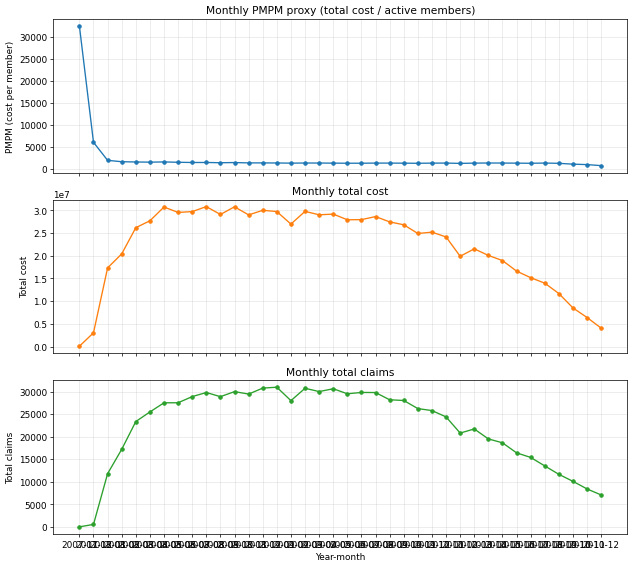

In [5]:
# --- Overall totals ---
total_spend = claims_all["cost"].sum()
unique_members = claims_all["member_id"].nunique()
total_claims = len(claims_all)
valid_dates = claims_all["claim_date"].dropna()
date_min = valid_dates.min() if len(valid_dates) > 0 else None
date_max = valid_dates.max() if len(valid_dates) > 0 else None

print("Overall totals:")
print(f"  Total spend:     {total_spend:,.2f}")
print(f"  Unique members: {unique_members:,}")
print(f"  Total claims:   {total_claims:,}")
print(f"  Date range:     {date_min} to {date_max}")

# --- Monthly summary (group by year_month) ---
monthly_summary = claims_all.groupby("year_month", dropna=False).agg(
    total_cost=("cost", "sum"),
    total_claims=("cost", "size"),
    active_members=("member_id", "nunique"),
    inpatient_claims=("is_inpatient", "sum"),
    outpatient_claims=("is_outpatient", "sum"),
).reset_index()
monthly_summary["inpatient_claims"] = monthly_summary["inpatient_claims"].astype(int)
monthly_summary["outpatient_claims"] = monthly_summary["outpatient_claims"].astype(int)
monthly_summary["pmpm_proxy"] = np.where(
    monthly_summary["active_members"] > 0,
    monthly_summary["total_cost"] / monthly_summary["active_members"],
    np.nan,
)

# --- Top 12 months by total_cost ---
top12 = monthly_summary.nlargest(12, "total_cost")[["year_month", "total_cost", "total_claims", "active_members", "pmpm_proxy"]]
print("\nTop 12 months by total_cost:")
display(top12)

# --- Charts: pmpm_proxy, total_cost, total_claims ---
# Sort by year_month for clean time order
ms = monthly_summary.dropna(subset=["year_month"]).sort_values("year_month")

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(ms["year_month"], ms["pmpm_proxy"], marker="o", markersize=4)
axes[0].set_ylabel("PMPM (cost per member)")
axes[0].set_title("Monthly PMPM proxy (total cost / active members)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(ms["year_month"], ms["total_cost"], marker="o", markersize=4, color="C1")
axes[1].set_ylabel("Total cost")
axes[1].set_title("Monthly total cost")
axes[1].grid(True, alpha=0.3)

axes[2].plot(ms["year_month"], ms["total_claims"], marker="o", markersize=4, color="C2")
axes[2].set_ylabel("Total claims")
axes[2].set_xlabel("Year-month")
axes[2].set_title("Monthly total claims")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Descriptive cost drivers (charts)

Visualize cost and utilization by key dimensions (e.g., age, gender, chronic conditions, year) using matplotlib.

Top 15 members by total_cost:


,member_id,total_cost,total_claims,inpatient_claims,outpatient_claims,active_months
0,CD57573A5B77AAFE,234190.0,55,14,41,21
1,E2D39E24FCF427D5,231280.0,46,9,37,18
2,3A9D94388C426924,213970.0,33,12,21,21
3,11B3642EFC2521EB,207120.0,40,8,32,29
4,AEF310232161AC91,205420.0,42,9,33,26
5,7E00D9D78DAA008D,199280.0,30,9,21,20
6,FC02104A9F15D57C,194930.0,37,13,24,22
7,F8F72B475A3381DC,193790.0,44,8,36,20
8,AEE2353E80207F0C,190250.0,13,9,4,9
9,8FBF91DCA969CB07,189380.0,42,5,37,18


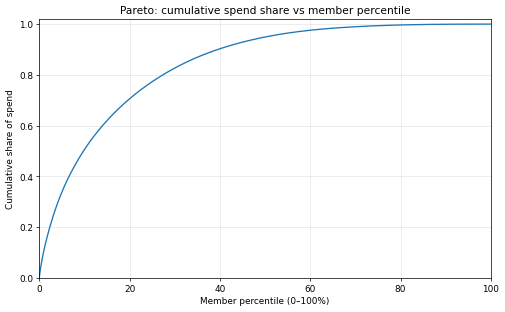

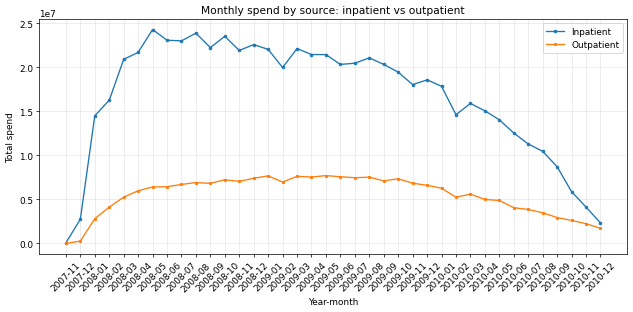

In [6]:
# --- Table: top 15 members by total_cost ---
top15_members = (
    member_summary.nlargest(15, "total_cost")[
        ["member_id", "total_cost", "total_claims", "inpatient_claims", "outpatient_claims", "active_months"]
    ]
    .reset_index(drop=True)
)
print("Top 15 members by total_cost:")
display(top15_members)

# --- Pareto: cumulative spend share vs member percentile ---
ms_sorted = member_summary.sort_values("total_cost", ascending=False).reset_index(drop=True)
total_spend_all = ms_sorted["total_cost"].sum()
n_members = len(ms_sorted)
if total_spend_all > 0 and n_members > 0:
    ms_sorted["cum_cost"] = ms_sorted["total_cost"].cumsum()
    ms_sorted["cum_share_spend"] = ms_sorted["cum_cost"] / total_spend_all
    ms_sorted["member_pct"] = 100 * (np.arange(1, n_members + 1, dtype=float) / n_members)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(ms_sorted["member_pct"], ms_sorted["cum_share_spend"], linewidth=1.5)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Member percentile (0–100%)")
    ax.set_ylabel("Cumulative share of spend")
    ax.set_title("Pareto: cumulative spend share vs member percentile")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# --- Spend mix over time: inpatient vs outpatient monthly spend (two-line plot) ---
monthly_by_source = (
    claims_all.groupby(["year_month", "source"])["cost"]
    .sum()
    .unstack(fill_value=0)
)
monthly_by_source = monthly_by_source.reindex(columns=["inpatient", "outpatient"], fill_value=0)
monthly_by_source = monthly_by_source.sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
if "inpatient" in monthly_by_source.columns:
    ax.plot(monthly_by_source.index, monthly_by_source["inpatient"], label="Inpatient", marker="o", markersize=3)
if "outpatient" in monthly_by_source.columns:
    ax.plot(monthly_by_source.index, monthly_by_source["outpatient"], label="Outpatient", marker="s", markersize=3)
ax.set_xlabel("Year-month")
ax.set_ylabel("Total spend")
ax.set_title("Monthly spend by source: inpatient vs outpatient")
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## High-cost cohorts

Rank members with a retained claim by observed payments. The top 1% sits inside the top 5%. The bottom 95% is the comparison group for the top 5%. These groups are defined using the same payments being summarized.

Comparison table (Top 1%, Top 5%, Bottom 95%):


,size,share_of_spend,mean_cost,median_cost,mean_claims,inpatient_rate
Top 1%,868,0.106528,104155.172811,96680.0,27.535714,1.000000
Top 5%,4336,0.337891,66133.927583,58890.0,21.180812,0.987315
Bottom 95%,82369,0.662109,6821.858466,3000.0,9.159635,0.406694


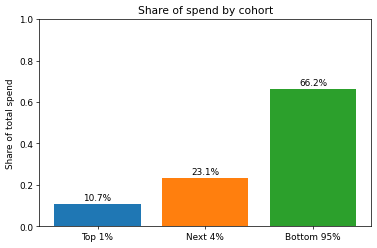

In [7]:
# Define cohorts by total_cost (sorted descending)
ms = member_summary.sort_values("total_cost", ascending=False).reset_index(drop=True)
n = len(ms)
total_spend = ms["total_cost"].sum()
n_1pct = max(1, int(np.ceil(0.01 * n)))
n_5pct = max(1, int(np.ceil(0.05 * n)))

top_1pct = ms.iloc[:n_1pct]
next_4pct = ms.iloc[n_1pct:n_5pct]   # top 5% excluding top 1%
top_5pct = ms.iloc[:n_5pct]
bottom_95pct = ms.iloc[n_5pct:]

def cohort_metrics(df, label):
    if len(df) == 0:
        return {"cohort": label, "size": 0, "share_of_spend": 0, "mean_cost": np.nan, "median_cost": np.nan, "mean_claims": np.nan, "inpatient_rate": np.nan}
    spend = df["total_cost"].sum()
    share = spend / total_spend if total_spend > 0 else 0
    return {
        "cohort": label,
        "size": len(df),
        "share_of_spend": share,
        "mean_cost": df["total_cost"].mean(),
        "median_cost": df["total_cost"].median(),
        "mean_claims": df["total_claims"].mean(),
        "inpatient_rate": (df["inpatient_claims"] >= 1).mean(),
    }

rows = [
    cohort_metrics(top_1pct, "Top 1%"),
    cohort_metrics(top_5pct, "Top 5%"),
    cohort_metrics(bottom_95pct, "Bottom 95%"),
]
comparison_table = pd.DataFrame(rows).set_index("cohort")
comparison_table.index.name = None
print("Comparison table (Top 1%, Top 5%, Bottom 95%):")
display(comparison_table)

# Bar chart: share of spend by cohort (Top 1%, Next 4%, Bottom 95%)
share_1 = top_1pct["total_cost"].sum() / total_spend if total_spend > 0 else 0
share_next4 = next_4pct["total_cost"].sum() / total_spend if total_spend > 0 else 0
share_bottom95 = bottom_95pct["total_cost"].sum() / total_spend if total_spend > 0 else 0
labels = ["Top 1%", "Next 4%", "Bottom 95%"]
shares = [share_1, share_next4, share_bottom95]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, shares, color=["C0", "C1", "C2"])
ax.set_ylabel("Share of total spend")
ax.set_title("Share of spend by cohort")
ax.set_ylim(0, 1)
for b, s in zip(bars, shares):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f"{100 * s:.1f}%", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

Correlation with total_cost (sorted):
Mean total_cost by sex:
Mean total_cost by age bin:


,correlation_with_total_cost
inpatient_claims,0.800117
avg_monthly_cost,0.577817
total_claims,0.491735
active_months,0.451446
outpatient_claims,0.398222
share_inpatient,0.352685
age,0.039425


,mean_total_cost,member_count
sex,,
Female,9824.64,48934
Male,9740.48,37771


,mean_total_cost,member_count
age_bin,,
<65,10181.02,13856
65-74,8444.03,33709
75-84,10306.00,25961
85+,11791.79,13179


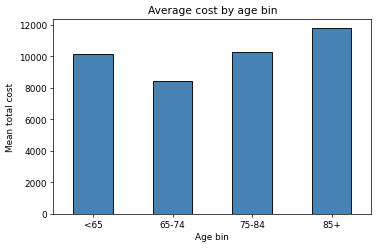

In [8]:
# --- Build features_df at member level ---
features_df = member_summary[
    ["member_id", "total_cost", "total_claims", "inpatient_claims", "outpatient_claims", "active_months", "avg_monthly_cost"]
].copy()
features_df["share_inpatient"] = np.where(
    features_df["total_claims"] > 0,
    features_df["inpatient_claims"] / features_df["total_claims"],
    np.nan,
)

# Merge beneficiary demographics if available (use member_id_col from Data dictionary)
bene = df_beneficiary.copy()
bene = bene.rename(columns={member_id_col: "member_id"})
merge_cols = ["member_id"] + [c for c in ["BENE_SEX_IDENT_CD", "BENE_BIRTH_DT", age_col] if c and c in bene.columns]
features_df = features_df.merge(bene[merge_cols], on="member_id", how="left")

# Sex: use BENE_SEX_IDENT_CD if present
if "BENE_SEX_IDENT_CD" in features_df.columns:
    features_df["sex"] = features_df["BENE_SEX_IDENT_CD"].astype(str).replace({"1": "Male", "2": "Female", "1.0": "Male", "2.0": "Female"})
else:
    features_df["sex"] = np.nan

# Age: derive from BENE_BIRTH_DT (YYYYMMDD) if present; use age at 2008-12-31 for bins
ref_date = pd.Timestamp("2008-12-31")
if "BENE_BIRTH_DT" in features_df.columns:
    birth_dt = parse_yyyymmdd(features_df["BENE_BIRTH_DT"])
    features_df["age"] = (ref_date - birth_dt).dt.days / 365.25
    features_df["age"] = features_df["age"].round().clip(lower=0).where(features_df["age"].notna())
elif age_col and age_col in features_df.columns:
    features_df["age"] = pd.to_numeric(features_df[age_col], errors="coerce")
else:
    features_df["age"] = np.nan

# Drop temporary merge columns if present
for c in ["BENE_SEX_IDENT_CD", "BENE_BIRTH_DT"] + ([age_col] if age_col else []):
    if c in features_df.columns:
        features_df = features_df.drop(columns=[c], errors="ignore")

# --- Correlation of numeric features vs total_cost (sorted) ---
num_cols = ["total_claims", "inpatient_claims", "outpatient_claims", "active_months", "avg_monthly_cost", "share_inpatient"]
if pd.notna(features_df["age"]).any():
    num_cols.append("age")
num_cols = [c for c in num_cols if c in features_df.columns]
corr_with_cost = features_df[num_cols].corrwith(features_df["total_cost"]).sort_values(ascending=False)
corr_table = pd.DataFrame({"correlation_with_total_cost": corr_with_cost})
print("Correlation with total_cost (sorted):")
display(corr_table)

# --- Grouped mean total_cost by sex (if available) ---
if "sex" in features_df.columns and features_df["sex"].notna().any():
    mean_by_sex = features_df.groupby("sex", dropna=False)["total_cost"].agg(["mean", "count"]).round(2)
    mean_by_sex.columns = ["mean_total_cost", "member_count"]
    print("Mean total_cost by sex:")
    display(mean_by_sex)
else:
    mean_by_sex = None
    print("Sex not available; skipping mean cost by sex.")

# --- Age bins and grouped mean total_cost ---
age_bins = [0, 65, 75, 85, 150]
age_labels = ["<65", "65-74", "75-84", "85+"]
features_df["age_bin"] = pd.cut(features_df["age"], bins=age_bins, labels=age_labels, right=False)

if features_df["age"].notna().any():
    mean_by_age = features_df.groupby("age_bin", observed=True)["total_cost"].agg(["mean", "count"]).round(2)
    mean_by_age.columns = ["mean_total_cost", "member_count"]
    print("Mean total_cost by age bin:")
    display(mean_by_age)

    # Single plot: avg cost by age bin
    fig, ax = plt.subplots(figsize=(6, 4))
    mean_by_age["mean_total_cost"].plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
    ax.set_xlabel("Age bin")
    ax.set_ylabel("Mean total cost")
    ax.set_title("Average cost by age bin")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()
else:
    mean_by_age = None
    print("Birth date or age could not be computed; skipping age bins and plot.")

## Interpreting the member profiles

Claim counts and inpatient use summarize how the observed payments accumulated. Some features are mechanically related to spending because they are built from the same claims. Age is approximated from birth year as of December 31, 2008 and describes the linked synthetic sample.

## Findings

- **$848.7 million in synthetic inpatient and outpatient payments** across 846,310 retained claim rows for 86,705 members with claims.
- **The top 1% accounted for 10.7% of payments and the top 5% for 33.8%.** The top 5% averaged 21.2 claim rows per member versus 9.2 in the bottom 95%.
- **98.7% of the top 5% had an inpatient claim**, compared with 40.7% in the bottom 95%. In a real payer analysis this would motivate a closer look at the inpatient payment mix and a review of whether the pattern persists across periods.

## Limitations

CMS designed DE-SynPUF for learning and development. The synthetic distributions do not support estimates for the real Medicare population. This analysis covers inpatient and outpatient claim rows only, excludes rows with missing claim dates, includes a small number of late-2007 claim dates, and uses only the 2008 beneficiary file for linked demographics. Covered months and utilization outside these claim types are outside the payment denominator. The analysis does not measure avoidable admissions or the effect of care management.